# Structural Estimation of Market Parameters

### Simultaneous Estimator, Truncated Normal with Variance, Optim Second Stage

### Summer 2025 Dataset

James Yu

In [1]:
using Pkg
Pkg.activate(".")
pkg_list = [
    "BlackBoxOptim", 
    "Cubature", 
    "Distributions", 
    "Integrals", 
    "Optim", 
    "Roots", 
    "FiniteDiff", 
    "PythonPlot", 
    "PrettyTables", 
    "JLD", 
    "StatProfilerHTML",
    "SpecialFunctions"
]
#for pkg in pkg_list 
#    Pkg.add(pkg)
#end

#Pkg.instantiate()

using BlackBoxOptim, Cubature, Distributions, Integrals, Optim, Random, Roots, FiniteDiff, PythonPlot, PrettyTables, JLD, SpecialFunctions

  Activating project at `C:\Users\jbrig\Documents\research\mapinator_2026`
    CondaPkg Found dependencies: C:\Users\jbrig\.julia\packages\PythonCall\Nr75f\CondaPkg.toml
    CondaPkg Found dependencies: C:\Users\jbrig\.julia\packages\PythonPlot\469aA\CondaPkg.toml
    CondaPkg Dependencies already up to date


# STEP 1: Get placements matrix

In [2]:
type_allocation_res = load("type_allocation_results_4_S2025.jld")
placement_rates_raw = type_allocation_res["placement_rates"]
unmatched_raw = type_allocation_res["unmatched"]
k = size(placement_rates_raw)[2]
K = size(placement_rates_raw)[1]

# conduct adjustment using the relative m_t values
m_t_values = type_allocation_res["m_t_values"]
m_t_placements = zeros(Int, k)
for t in 1:k
    m_t_placements[t] = sum(placement_rates_raw[:, t]) + unmatched_raw[t]
end

placement_rates_rescaled = zeros(Int, K, k)
for i in 1:K
    for t in 1:k
        placement_rates_rescaled[i, t] = round(m_t_values[t] * (placement_rates_raw[i, t] / m_t_placements[t]))
    end
end

# collapse the last three sinks together
println("original dimensions: ", K, " by ", k)
K -= 2
K -= 1
println("new dimensions: ", K, " by ", k)

placement_rates = zeros(Int, K, k)
for i in 1:3 # NOTE: hardcoded
    for t in 1:k
        placement_rates[i, t] = placement_rates_rescaled[i, t]
    end
end

for i in 4:7 # NOTE: hardcoded
    for t in 1:k
        placement_rates[i-1, t] += placement_rates_rescaled[i, t]
    end
end

for t in 1:k
    for original_sink_tier in [K+2, K+3] # NOTE: hardcoded
        placement_rates[K, t] += placement_rates_rescaled[original_sink_tier, t] 
    end
end

estimated_m_val = sum(m_t_values[1:k])
estimated_γ = m_t_values[1:k] / estimated_m_val

original dimensions: 9 by 4
new dimensions: 6 by 4


4-element Vector{Float64}:
 0.23432557385027172
 0.3223294671100657
 0.2747992537918728
 0.16854570524778975

In [3]:
placement_rates_raw_table = zeros(Int, K, k)
for i in 1:3 # NOTE: hardcoded
    for t in 1:k
        placement_rates_raw_table[i, t] = placement_rates_raw[i, t]
    end
end

for i in 4:7 # NOTE: hardcoded
    for t in 1:k
        placement_rates_raw_table[i-1, t] += placement_rates_raw[i, t]
    end
end

for t in 1:k
    for original_sink_tier in [K+2, K+3] # NOTE: hardcoded
        placement_rates_raw_table[K, t] += placement_rates_raw[original_sink_tier, t] 
    end
end

In [4]:
placement_rates_raw

9×4 Matrix{Int64}:
 1142   209   58    4
 1624  1164  245   47
 1124  1545  764  115
   86   234  267  402
  817   751  383  128
  903   624  279   98
  275   283  164   51
  204   417  528  399
  586   969  660  374

In [5]:
placement_rates

6×4 Matrix{Int64}:
  809   191    73     6
 1150  1066   307    66
  857  1629  1294   724
  579   688   481   179
  640   571   350   137
  754  1528  1697  1154

In [6]:
m_t_values

4-element Vector{Int64}:
 5778
 7948
 6776
 4156

In [7]:
include("type_allocation_base.jl")

Main.SBM

In [8]:
sink_names_to_present = [
    "Tier 3 + Tier 4",
    "Public Sector",
    "Private Sector",
    "Other"
]
SBM.nice_table(placement_rates_raw_table, k, k-2, 4, sink_names_to_present)

┌─────────────────┬────────┬────────┬────────┬────────┬────────────┐
│                 │ Tier 1 │ Tier 2 │ Tier 3 │ Tier 4 │ Row Totals │
├─────────────────┼────────┼────────┼────────┼────────┼────────────┤
│          Tier 1 │   1142 │    209 │     58 │      4 │       1413 │
│          Tier 2 │   1624 │   1164 │    245 │     47 │       3080 │
│ Tier 3 + Tier 4 │   1210 │   1779 │   1031 │    517 │       4537 │
│   Public Sector │    817 │    751 │    383 │    128 │       2079 │
│  Private Sector │    903 │    624 │    279 │     98 │       1904 │
│           Other │   1065 │   1669 │   1352 │    824 │       4910 │
│   Column Totals │   6761 │   6196 │   3348 │   1618 │      17923 │
└─────────────────┴────────┴────────┴────────┴────────┴────────────┘
\begin{tabular}{rrrrrr}
  \hline
   & \textbf{Tier 1} & \textbf{Tier 2} & \textbf{Tier 3} & \textbf{Tier 4} & \textbf{Row Totals} \\\hline
  Tier 1 & 1142 & 209 & 58 & 4 & 1413 \\
  Tier 2 & 1624 & 1164 & 245 & 47 & 3080 \\
  Tier 3 + Tier 4

In [9]:
SBM.nice_table(placement_rates, k, k-2, 4, sink_names_to_present)

┌─────────────────┬────────┬────────┬────────┬────────┬────────────┐
│                 │ Tier 1 │ Tier 2 │ Tier 3 │ Tier 4 │ Row Totals │
├─────────────────┼────────┼────────┼────────┼────────┼────────────┤
│          Tier 1 │    809 │    191 │     73 │      6 │       1079 │
│          Tier 2 │   1150 │   1066 │    307 │     66 │       2589 │
│ Tier 3 + Tier 4 │    857 │   1629 │   1294 │    724 │       4504 │
│   Public Sector │    579 │    688 │    481 │    179 │       1927 │
│  Private Sector │    640 │    571 │    350 │    137 │       1698 │
│           Other │    754 │   1528 │   1697 │   1154 │       5133 │
│   Column Totals │   4789 │   5673 │   4202 │   2266 │      16930 │
└─────────────────┴────────┴────────┴────────┴────────┴────────────┘
\begin{tabular}{rrrrrr}
  \hline
   & \textbf{Tier 1} & \textbf{Tier 2} & \textbf{Tier 3} & \textbf{Tier 4} & \textbf{Row Totals} \\\hline
  Tier 1 & 809 & 191 & 73 & 6 & 1079 \\
  Tier 2 & 1150 & 1066 & 307 & 66 & 2589 \\
  Tier 3 + Tier 4 

In [10]:
pretty_table(reshape(m_t_values, 1, k), header = ["Tier $i" for i in 1:k], backend=Val(:latex))

\begin{tabular}{rrrr}
  \hline
  \textbf{Tier 1} & \textbf{Tier 2} & \textbf{Tier 3} & \textbf{Tier 4} \\\hline
  5778 & 7948 & 6776 & 4156 \\\hline
\end{tabular}


In [11]:
function Fx(t, α, v_rel)
    return 1 - sum([-log(v_rel[j])*sum(α[1:j]) for j in 1:t])
end

function F(x, ρ, normals, K)
    sum_base = 0.0
    for i in 1:K
        sum_base += ρ[i] * cdf(normals[i], x)
    end
    return sum_base
end

function f_integrand(integrals, x, p) 
    base_exp = exp(F(x, p.ρ, p.normals, p.K) / sum(p.α[1:p.s]))
    for i in 1:p.K
        integrals[i] = base_exp * pdf(p.normals[i], x)
    end
end

function get_integrals(x_vec, ρ, normals, α, k, K)
    # Fx_vec = [F(x0)=1, F(x1), F(x2), F(x3), ..., F(xk-1)]
    # x_vec = [x0 = 1, x1, x2, x3, ..., xk = 0]
    # x_vec[s] = x_{s-1}, so the limits of integration are and must be offset by 1 below
    all_integrals = zeros(K, k)
    for s in 1:k
        # https://docs.sciml.ai/Integrals/stable/basics/SampledIntegralProblem/ might be faster
        # if f_integrand(x) can be vectorized/sped up
        prob = IntegralProblem(IntegralFunction(f_integrand, zeros(K)), (x_vec[s+1], x_vec[s]), (; s, ρ, normals, α, K))
        sol = solve(prob, CubatureJLh(); reltol = 1e-3, abstol = 1e-3)
        integrals_result = sol.u
        # NOTE: result may be inf if alpha_1 is too small
        # NOTE: some parameter values for μ and σ may cause the cdf F_i to be NaN
        for i in 1:K 
            all_integrals[i, s] = integrals_result[i]
            #if integrals_result[i] == 0.0
            #    println((F(x_vec[s], ρ, normals, K), F(x_vec[s+1], ρ, normals, K), x_vec, s, normals[i]))
            #end
        end
    end
    return all_integrals
end      

function q(i, t, all_integrals, Fx_vec, α, v_rel, k)
    return α[t] * sum([(1/sum(α[1:s])) * prod([v_rel[j] for j in t:(s-1)]) * exp(-Fx_vec[s] / sum(α[1:s])) * all_integrals[i, s] for s in t:k])
end

q (generic function with 1 method)

# STEP 2: Estimate global maximum likelihood

In [12]:
function estimate_likelihood_2(p_vec, γ, placements, k, K, m_val, counter; get_full = false)   
    μ = p_vec[1:K]
    σ = p_vec[K+1:2K]

    for i in 1:K
        if abs(abs(erf((-μ[i]/σ[i]) / sqrt(2))) - 1) < 1e-3
            if get_full
                return -Inf
            else
                return Inf
            end
        end
    end

    
    ρ_vec = p_vec[2K+1:3K]
    ρ = ρ_vec / sum(ρ_vec)

    v_rel = p_vec[3K+1:3K+k-1]
    τ = p_vec[3K+k]
    α = γ * τ

    ## compute the cutoffs x and the CDF values F(x)
    normals = [truncated(Normal(μ[i], σ[i]), 0, 1) for i in 1:K]

    Fx_vec = ones(k) # sets F(x0) = 1 by default; Fx_vec = [F(x0)=1, F(x1), F(x2), F(x3), ..., F(xk-1)]
    x_vec = ones(k+1) # x_vec = [x0 = 1, x1, x2, x3, ..., xk = 0]
    x_vec[k+1] = 0.0
    for t in 1:k-1
        Fx_vec_candidate = Fx(t, α, v_rel)
        if Fx_vec_candidate <= 0.0 # if τ * sum(log(v_rel)) is too negative (v_rel too small, τ too big), Fx_vec[i] < 0 can occur
            Fx_vec[t+1:k] .= 0.0
            x_vec[t+1:k] .= 0.0
            break
        end

        Fx_vec[t+1] = Fx_vec_candidate
        # there is no simple closed-form for F^{-1}(x) so this numerically computes x1, x2, x3
        x_vec[t+1] = find_zero(x -> F(x, ρ, normals, K) - Fx_vec[t+1], 0.5) 
    end 

    ρ_q_it = zeros(K, k)
    all_integrals = get_integrals(x_vec, ρ, normals, α, k, K)
    for i in 1:K, t in 1:k
        prob = q(i, t, all_integrals, Fx_vec, α, v_rel, k)
        ρ_q_it[i, t] = ρ[i] * prob
    end

    normalizer = sum(ρ_q_it)
    
    likelihood = 0.0
    for i in 1:K, t in 1:k
        likelihood += placements[i, t] * log(ρ_q_it[i, t] / normalizer)
    end

    counter[1] += 1
    if get_full == true
        likelihood_probability_vector = zeros((k * K))
        total_placements_vector = zeros((k * K))
        vector_counter = 1
        for i in 1:K
            for t in 1:k
                likelihood_probability_vector[vector_counter] = (ρ_q_it[i, t] / normalizer)
                if isnan(likelihood_probability_vector[vector_counter])
                    return -Inf
                end
                total_placements_vector[vector_counter] = placements[i, t]
                vector_counter += 1
            end
        end
        actual_likelihood = loglikelihood(Multinomial(sum(placements), likelihood_probability_vector), total_placements_vector)
        return actual_likelihood
    else
        return -likelihood
    end
end

estimate_likelihood_2 (generic function with 1 method)

In [13]:
# upper/lower bound on the mu parameter of truncated normal
upper_1 = [10.0 for _ in 1:K]
lower_1 = [-10.0 for _ in 1:K]

upper_1[K] = 0.0

# upper/lower bound on the sigma parameter of truncated normal
append!(upper_1, [10.0 for _ in 1:K])
append!(lower_1, [0.0001 for _ in 1:K])

upper_1[2K] = 0.1

# upper/lower bound on values proportional to ρ_i
append!(upper_1, [1.0 for _ in 1:K])
append!(lower_1, [0.0 for _ in 1:K])

# upper/lower bound on v_rel
append!(upper_1, [1.0 for _ in 1:k-1])
append!(lower_1, [0.01 for _ in 1:k-1])

# upper/lower bound on τ
append!(upper_1, [10.0 for _ in 1:1])
append!(lower_1, [0.25 for _ in 1:1])

search_range_1 = [(lower_1[i], upper_1[i]) for i in eachindex(upper_1)]

Random.seed!(0)
NUM_ROUNDS = 19

likelihoods = zeros(NUM_ROUNDS)
sols = zeros(NUM_ROUNDS, length(upper_1))

# this approach with random re-running is similar to that used in/associated with 
#     the SBM MCMC solver package associated with Peixoto (2014)
Threads.@threads for SEED in 1:NUM_ROUNDS
    println("starting round $SEED")
    counter = [0]
    sol_res_1 = bboptimize(p -> estimate_likelihood_2(p, estimated_γ, placement_rates, k, K, estimated_m_val, counter), SearchRange = search_range_1, MaxTime = 600.0, TraceMode = :silent) 
    # MaxTime = 60.0, MaxFuncEvals = 500000,
    sol_1 = best_candidate(sol_res_1)
    actual_likelihood = estimate_likelihood_2(sol_1, estimated_γ, placement_rates, k, K, estimated_m_val, counter; get_full = true)
    likelihoods[SEED] = actual_likelihood
    sols[SEED, :] = sol_1[:]
    estimated_v_rel = sol_1[3K+1:3K+k-1]
    estimated_τ = sol_1[3K+k]
    println("  finished round $SEED with likelihood $actual_likelihood in $(counter[1]) iters")
    println("  ", estimated_v_rel, " ", estimated_τ)
end

best_likelihood = maximum(likelihoods)
best_index = argmax(likelihoods)
best_sol = sols[best_index, :]
println("best likelihood: $best_likelihood")
estimated_v_rel = best_sol[3K+1:3K+k-1]
estimated_τ = best_sol[3K+k]
println(estimated_v_rel)
println(estimated_τ)

starting round 9
starting round 1
starting round 5
starting round 15
starting round 11
starting round 10
starting round 19
starting round 7
starting round 2
starting round 8
starting round 4
starting round 18
starting round 13
starting round 3
starting round 6
starting round 16
starting round 12
starting round 17
starting round 14
  finished round 18 with likelihood -99.17397438944909 in 667808 iters
  finished round 11 with likelihood -99.17400728435587 in 671978 iters
  finished round 17 with likelihood -99.17400774675707 in 669812 iters
  finished round 8 with likelihood -99.17402752510225 in 662376 iters
  finished round 14 with likelihood -99.17402834523818 in 656942 iters
  finished round 9 with likelihood -99.17399939818824 in 666904 iters
  finished round 3 with likelihood -99.17396746325312 in 661145 iters
  finished round 2 with likelihood -99.17425794285964 in 685266 iters
  finished round 16 with likelihood -99.17399165983988 in 663089 iters
  finished round 6 with likeliho

In [14]:
sol_1 = best_sol

22-element Vector{Float64}:
  0.24307584875471588
  0.15609199106134677
 -0.7017158371221792
 -0.22210884330342845
 -0.45778252856710094
 -8.895391984547612e-10
  0.1451307681154134
  0.07583976137980437
  0.21325338199689187
  0.19331944442445234
  0.2835410984083005
  0.03613964027950677
  0.12457864204547844
  0.3302547310398942
  0.7450397182741547
  0.2834379515196566
  0.23979685086959118
  0.9663392349948577
  0.65520064257931
  0.7870536676962879
  0.8366786899535466
  0.9005779528705795

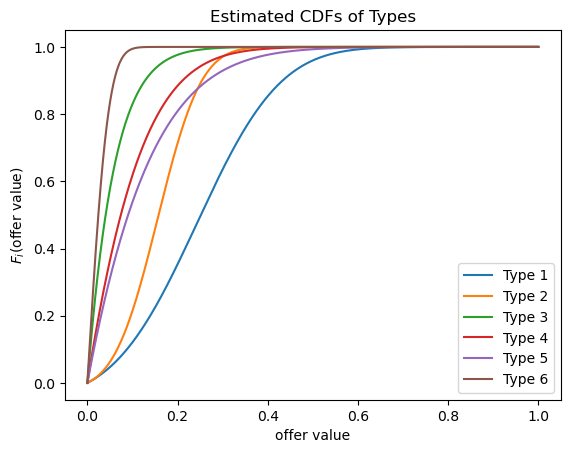

In [15]:
point_grid = [i for i in range(0, 1; length = 10001)]
for select_type in 1:K
    plot(point_grid, [cdf(truncated(Normal(sol_1[select_type], sol_1[select_type+K]), 0, 1), x) for x in point_grid], label = string("Type ", select_type))
end

title("Estimated CDFs of Types")
xlabel("offer value")
ylabel("\$F_i\$(offer value\$)\$")
legend();

# STEP 3: locally improve the estimate

In [16]:
function estimate_likelihood_3(p_vec, μ_K, σ_K, γ, placements, k, K, m_val)   
    Km1 = K - 1
    μ = zeros(K)
    σ = zeros(K)
    μ[1:Km1] = p_vec[1:Km1]
    σ[1:Km1] = p_vec[Km1+1:2Km1]
    μ[K] = μ_K
    σ[K] = σ_K
    
    ρ = zeros(K)
    ρ[1:Km1] = p_vec[2Km1+1:3Km1]
    ρ[K] = 1 - sum(ρ[1:Km1])
    v_rel = p_vec[3Km1+1:3Km1+k-1]
    τ = p_vec[3Km1+k]
    α = γ * τ

    ## compute the cutoffs x and the CDF values F(x)
    normals = [truncated(Normal(μ[i], σ[i]), 0, 1) for i in 1:K]

    Fx_vec = ones(k) # sets F(x0) = 1 by default; Fx_vec = [F(x0)=1, F(x1), F(x2), F(x3), ..., F(xk-1)]
    x_vec = ones(k+1) # x_vec = [x0 = 1, x1, x2, x3, ..., xk = 0]
    x_vec[k+1] = 0.0
    for t in 1:k-1
        Fx_vec_candidate = Fx(t, α, v_rel)
        if Fx_vec_candidate <= 0.0
            Fx_vec[t+1:k] .= 0.0
            x_vec[t+1:k] .= 0.0
            break
        end

        Fx_vec[t+1] = Fx_vec_candidate
        # there is no simple closed-form for F^{-1}(x) so this numerically computes x1, x2, x3
        x_vec[t+1] = find_zero(x -> F(x, ρ, normals, K) - Fx_vec[t+1], 0.5) 
    end 

    ρ_q_it = zeros(K, k)
    all_integrals = get_integrals(x_vec, ρ, normals, α, k, K)
    for i in 1:K, t in 1:k
        prob = q(i, t, all_integrals, Fx_vec, α, v_rel, k)
        ρ_q_it[i, t] = ρ[i] * prob
    end

    normalizer = sum(ρ_q_it)
    likelihood = 0.0
    for i in 1:K, t in 1:k
        likelihood += placements[i, t] * log(ρ_q_it[i, t] / normalizer)
    end

    if isnan(likelihood) || isinf(likelihood)
        println(likelihood)
    end

    return -likelihood
end

estimate_likelihood_3 (generic function with 1 method)

In [17]:
function get_initial_condition(p_vec, k, K)
    Km1 = K - 1
    output = zeros(3Km1 + k)
    output[1:Km1] = p_vec[1:Km1]
    output[Km1+1:2Km1] = p_vec[K+1:K + Km1]
    ρ_vec = p_vec[2K+1:3K] / sum(p_vec[2K+1:3K])
    output[2Km1+1:3Km1] = ρ_vec[1:Km1]
    output[3Km1+1:3Km1+k] = p_vec[3K+1:3K+k]
    return output
end

function con_c!(c, x) 
    Km1 = K - 1
    c[1] = 1 - sum(x[2Km1+1:3Km1])
    #for i in 1:K
    #   c[i+1] = abs(abs(erf((-x[i]/x[K+i]) / sqrt(2))) - 1)
    #end
    c
end

con_c! (generic function with 1 method)

In [18]:
Random.seed!(0)

# upper/lower bound on the mu parameter of truncated normal
upper_2 = [5.0 for _ in 1:K-1]
lower_2 = [-5.0 for _ in 1:K-1]

# upper/lower bound on the sigma parameter of truncated normal
append!(upper_2, [10.0 for _ in 1:K-1])
append!(lower_2, [0.001 for _ in 1:K-1])

#upper_2[K] = sol_1[K]
#lower_2[K] = sol_1[K]
#upper_2[2K] = sol_1[2K]
#lower_2[2K] = sol_1[2K]

# upper/lower bound on ρ_i
append!(upper_2, [1.0 for _ in 1:K-1])
append!(lower_2, [0.0 for _ in 1:K-1])

# upper/lower bound on v_rel
append!(upper_2, [1.0 for _ in 1:k-1])
append!(lower_2, [0.01 for _ in 1:k-1])

# upper/lower bound on τ
append!(upper_2, [10.0 for _ in 1:1])
append!(lower_2, [0.25 for _ in 1:1])

x0 = get_initial_condition(sol_1, k, K)
lx = lower_2
ux = upper_2
lc = [0.0]
uc = [1.0]

#append!(uc, [Inf for _ in 1:K])
#append!(lc, [1e-3 for _ in 1:K])
println(con_c!(zeros(1), x0))
df = TwiceDifferentiable(p -> estimate_likelihood_3(p, sol_1[K], sol_1[2K], estimated_γ, placement_rates, k, K, estimated_m_val), x0)
dfc = TwiceDifferentiableConstraints(con_c!, lx, ux, lc, uc)
sol_res_2 = optimize(df, dfc, x0, IPNewton())
sol_2 = Optim.minimizer(sol_res_2)

[0.3593077642862159]


19-element Vector{Float64}:
  0.251491796517451
  0.1595359574484305
 -1.8166647180878195
 -0.40657793416758103
 -1.0184223898035134
  0.15914788460172244
  0.0814145946463931
  0.3300967997239254
  0.2391330201444815
  0.3931799886576407
  0.0463475892239166
  0.12290831554486406
  0.2774523835009817
  0.10549206972236172
  0.08917393048018421
  0.6547245197515345
  0.7877242666799898
  0.835332745966517
  0.8998449773504902

In [19]:
x0

19-element Vector{Float64}:
  0.24307584875471588
  0.15609199106134677
 -0.7017158371221792
 -0.22210884330342845
 -0.45778252856710094
  0.1451307681154134
  0.07583976137980437
  0.21325338199689187
  0.19331944442445234
  0.2835410984083005
  0.04632128317899858
  0.12279651364411531
  0.27702337417660927
  0.10538892863533028
  0.08916213607873065
  0.65520064257931
  0.7870536676962879
  0.8366786899535466
  0.9005779528705795

In [20]:
sol_res_2

 * Status: success

 * Candidate solution
    Final objective value:     4.914775e+04

 * Found with
    Algorithm:     Interior Point Newton

 * Convergence measures
    |x - x'|               = 0.00e+00 ≤ 0.0e+00
    |x - x'|/|x'|          = 0.00e+00 ≤ 0.0e+00
    |f(x) - f(x')|         = 0.00e+00 ≤ 0.0e+00
    |f(x) - f(x')|/|f(x')| = 0.00e+00 ≤ 0.0e+00
    |g(x)|                 = 5.92e-03 ≰ 1.0e-08

 * Work counters
    Seconds run:   17  (vs limit Inf)
    Iterations:    57
    f(x) calls:    226
    ∇f(x) calls:   226


In [21]:
x0 - sol_2

19-element Vector{Float64}:
 -0.008415947762735132
 -0.003443966387083719
  1.1149488809656403
  0.18446909086415259
  0.5606398612364125
 -0.014017116486309045
 -0.005574833266588725
 -0.11684341772703355
 -0.04581357572002917
 -0.1096388902493402
 -2.6306044918024407e-5
 -0.00011180190074874807
 -0.00042900932437245354
 -0.00010314108703143865
 -1.1794401453560366e-5
  0.00047612282777553805
 -0.00067059898370192
  0.0013459439870295853
  0.0007329755200893295

In [22]:
Km1 = K - 1
estimated_v_rel = sol_2[3Km1+1:3Km1+k-1]
estimated_τ = sol_2[3Km1+k]

0.8998449773504902

In [23]:
println("estimated value ratios:")
display(estimated_v_rel)
println()
estimated_v_base = 1
for i in 1:k
    println("v", i, ": ", estimated_v_base)
    if i != k
        estimated_v_base = estimated_v_rel[i] * estimated_v_base
    end
end
println()

println("estimated market balance ratio (m / (n-1)): ", estimated_τ)

#estimated_n_val = (estimated_m_val / estimated_τ) + 1
#println("estimated total departments: ", estimated_n_val)
estimated_α = estimated_τ * estimated_γ
println("estimated α_t: ", estimated_α)

estimated value ratios:


3-element Vector{Float64}:
 0.6547245197515345
 0.7877242666799898
 0.835332745966517


v1: 1
v2: 0.6547245197515345
v3: 0.515742392198686
v4: 0.43081650868666876

estimated market balance ratio (m / (n-1)): 0.8998449773504902
estimated α_t: [0.21085669069393836, 0.2900465520310527, 0.24727672830427938, 0.15166500632121976]


In [24]:
estimated_μ = sol_2[1:Km1]
estimated_σ = sol_2[Km1+1:2Km1]
estimated_ρ = sol_2[2Km1+1:3Km1];

In [25]:
estimated_μ

5-element Vector{Float64}:
  0.251491796517451
  0.1595359574484305
 -1.8166647180878195
 -0.40657793416758103
 -1.0184223898035134

In [26]:
estimated_σ

5-element Vector{Float64}:
 0.15914788460172244
 0.0814145946463931
 0.3300967997239254
 0.2391330201444815
 0.3931799886576407

In [27]:
estimated_ρ

5-element Vector{Float64}:
 0.0463475892239166
 0.12290831554486406
 0.2774523835009817
 0.10549206972236172
 0.08917393048018421

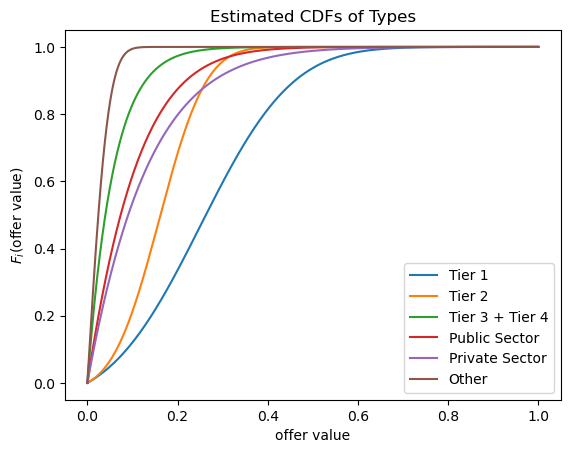

Python: None

In [28]:
point_grid = [i for i in range(0, 1; length = 10001)]
plot_labels = ["Tier 1", "Tier 2", "Tier 3 + Tier 4", 
    "Public Sector",
    "Private Sector",
    "Other"]
for select_type in 1:Km1
    plot(point_grid, [cdf(truncated(Normal(sol_2[select_type], sol_2[select_type+Km1]), 0, 1), x) for x in point_grid], label = plot_labels[select_type])
end
plot(point_grid, [cdf(truncated(Normal(sol_1[K], sol_1[2K]), 0, 1), x) for x in point_grid], label = plot_labels[K])
title("Estimated CDFs of Types")
xlabel("offer value")
ylabel("\$F_i\$(offer value\$)\$")
legend();
savefig("final_cdfs_.png", dpi = 800)

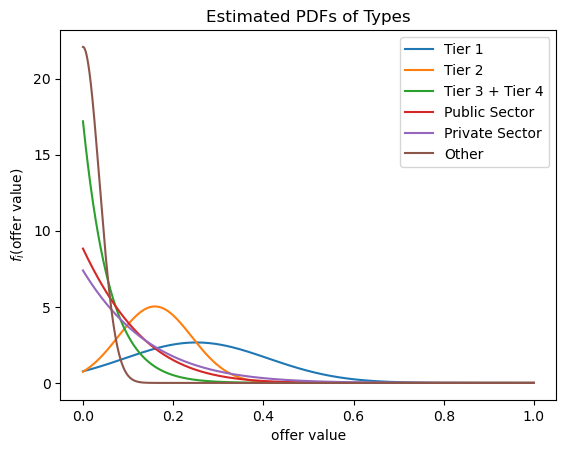

Python: None

In [29]:
point_grid = [i for i in range(0, 1; length = 10001)]
for select_type in 1:Km1
    plot(point_grid, [pdf(truncated(Normal(sol_2[select_type], sol_2[select_type+Km1]), 0, 1), x) for x in point_grid], label = plot_labels[select_type])
end
plot(point_grid, [pdf(truncated(Normal(sol_1[K], sol_1[2K]), 0, 1), x) for x in point_grid], label = plot_labels[K])
title("Estimated PDFs of Types")
xlabel("offer value")
ylabel("\$f_i\$(offer value\$)\$")
legend();
savefig("final_pdfs_.png", dpi = 800)

In [30]:
for select_type in 1:Km1
    println("Type $(select_type):")
    println("  est. mean:   ", mean(truncated(Normal(sol_2[select_type], sol_2[select_type+Km1]), 0, 1)))
    println("  est. stddev: ", std(truncated(Normal(sol_2[select_type], sol_2[select_type+Km1]), 0, 1)))
    println()
end

println("Type $K:")
    println("  est. mean:   ", mean(truncated(Normal(sol_1[K], sol_1[2K]), 0, 1)))
    println("  est. stddev: ", std(truncated(Normal(sol_1[K], sol_1[2K]), 0, 1)))
    println()

Type 1:
  est. mean:   0.27080868514506196
  est. stddev: 0.14175968780231418

Type 2:
  est. mean:   0.16442033001804326
  est. stddev: 0.07632329966405862

Type 3:
  est. mean:   0.05655046397391361
  est. stddev: 0.05507003200608341

Type 4:
  est. mean:   0.09812314574542891
  est. stddev: 0.08753101133690042

Type 5:
  est. mean:   0.12377990940105854
  est. stddev: 0.11465974913738079

Type 6:
  est. mean:   0.028835260688746853
  est. stddev: 0.02178534633403987



In [31]:
function estimate_likelihood_2_for_variance(p_vec, μ_K, σ_K, γ, placements, k, K, show_m = false)   
    Km1 = K - 1
    μ = zeros(K)
    σ = zeros(K)
    μ[1:Km1] = p_vec[1:Km1]
    σ[1:Km1] = p_vec[Km1+1:2Km1]
    μ[K] = μ_K
    σ[K] = σ_K
    
    ρ = zeros(K)
    ρ[1:Km1] = p_vec[2Km1+1:3Km1]
    ρ[K] = 1 - sum(ρ[1:Km1])
    v_rel = p_vec[3Km1+1:3Km1+k-1]
    τ = p_vec[3Km1+k]
    α = γ * τ

    ## compute the cutoffs x and the CDF values F(x)
    normals = [truncated(Normal(μ[i], σ[i]), 0, 1) for i in 1:K]

    Fx_vec = ones(k) # sets F(x0) = 1 by default; Fx_vec = [F(x0)=1, F(x1), F(x2), F(x3), ..., F(xk-1)]
    x_vec = ones(k+1) # x_vec = [x0 = 1, x1, x2, x3, ..., xk = 0]
    x_vec[k+1] = 0.0
    for t in 1:k-1
        Fx_vec_candidate = Fx(t, α, v_rel)
        if Fx_vec_candidate <= 0.0 # TODO: if this case occurs, can we speed up q()?
            Fx_vec[t+1:k] .= 0.0
            x_vec[t+1:k] .= 0.0
            break
        end
        Fx_vec[t+1] = Fx_vec_candidate
        # there is no simple closed-form for F^{-1}(x) so this numerically computes x1, x2, x3
        x_vec[t+1] = find_zero(x -> F(x, ρ, normals, K) - Fx_vec[t+1], 0.5) 
    end 

    ρ_q_it = zeros(K, k)
    all_integrals = get_integrals(x_vec, ρ, normals, α, k, K)
    for i in 1:K, t in 1:k
        prob = q(i, t, all_integrals, Fx_vec, α, v_rel, k)
        ρ_q_it[i, t] = ρ[i] * prob
    end

    normalizer = sum(ρ_q_it)
    if show_m
        println("n: ", sum(placements) / normalizer)
        println("m: ", τ * ((sum(placements) / normalizer) - 1))
    end
    
    likelihood_probability_vector = zeros(k * K)
    total_placements_vector = zeros(k * K)
    vector_counter = 1
    for i in 1:K
        for t in 1:k
            likelihood_probability_vector[vector_counter] = (ρ_q_it[i, t] / normalizer)
            total_placements_vector[vector_counter] = placements[i, t]
            vector_counter += 1
        end
    end
    M = sum(placements)
    actual_likelihood = loglikelihood(Multinomial(M, likelihood_probability_vector), total_placements_vector)
    return actual_likelihood
end

estimate_likelihood_2_for_variance (generic function with 2 methods)

In [32]:
sol_1_for_variance = sol_2

19-element Vector{Float64}:
  0.251491796517451
  0.1595359574484305
 -1.8166647180878195
 -0.40657793416758103
 -1.0184223898035134
  0.15914788460172244
  0.0814145946463931
  0.3300967997239254
  0.2391330201444815
  0.3931799886576407
  0.0463475892239166
  0.12290831554486406
  0.2774523835009817
  0.10549206972236172
  0.08917393048018421
  0.6547245197515345
  0.7877242666799898
  0.835332745966517
  0.8998449773504902

In [33]:
estimate_likelihood_2_for_variance(sol_1_for_variance, sol_1[K], sol_1[2K], estimated_γ, placement_rates, k, K, true)

n: 28629.40336661679
m: 25761.12497901398


-99.15463848298305

In [34]:
estimated_m_val

24658

In [35]:
likelihood_hessian = FiniteDiff.finite_difference_hessian(p -> estimate_likelihood_2_for_variance(p, sol_1[K], sol_1[2K], estimated_γ, placement_rates, k, K), sol_1_for_variance)

19×19 LinearAlgebra.Symmetric{Float64, Matrix{Float64}}:
 -12917.9     10299.6     103.026   …     604.165    187.769     231.175
  10299.6    -69161.2    1486.85        11896.9     4122.46    -5349.81
    103.026    1486.85   -200.382        -644.98     -45.2955    241.99
    492.255    4100.85     63.8684       -442.5       73.8593    439.593
    295.6      1979.72     20.2597       -188.931     35.5169    248.731
   -810.69      889.18    -29.4405  …    -535.29     -71.3892    -13.4834
   8442.29   -13474.2     146.28        -1118.15   -3338.74    -2174.31
   1217.53    17496.1   -2343.97        -7534.77    -518.291    2850.48
   2437.94    19737.2     290.058       -2014.19     359.117    2059.39
   1871.19    12317.2     123.954       -1137.41     215.221    1530.35
 -13567.1     25561.4   -1330.98    …  -24217.2    -6108.09    30143.7
    892.665   -3293.15   -861.704      -24447.5    -6694.4     22973.0
    121.829    3120.2   -1803.95        -5787.28   -2822.71     5214.6
    5

In [36]:
estimator_variance = inv((-1 * likelihood_hessian))

19×19 LinearAlgebra.Symmetric{Float64, Matrix{Float64}}:
  0.00156419    0.000930434  -0.000487686  …   0.000861685   0.00137936
  0.000930434   0.000597587  -0.000235507      0.000556511   0.000848618
 -0.000487686  -0.000235507   1.39096         -0.000145588  -0.000192094
 -0.000977586  -0.000324371  -0.00809958       0.000373039   0.000198641
 -0.000623788  -0.000215808  -0.0799917        0.000129298  -0.000400951
  0.000827266   0.000507122   6.81686e-5   …   0.000392871   0.000649062
  0.000442554   0.000258841  -0.000271971      0.000206027   0.000341785
  0.000963018   0.000606111  -0.118454         0.000563404   0.000798807
  0.0011042     0.00063454    0.00133173       0.000455547   0.000780403
  0.00147295    0.000894456   0.0122659        0.000786779   0.00134186
  1.85025e-5    1.27987e-5   -2.23676e-5   …   2.24462e-5    6.9176e-5
  2.44678e-5    1.30502e-5   -4.78485e-5       2.99868e-5    0.000113349
 -0.000145958  -9.30323e-5   -0.000558455     -9.4555e-5    -0.00014480

In [37]:
println([estimator_variance[i, i] for i in 1:3Km1+k]) # variance estimates

[0.0015641852470421195, 0.0005975868456395674, 1.3909575280329525, 0.09607037561056839, 0.16453641366056887, 0.0014457762153540922, 0.00016960334354740441, 0.01072569473639399, 0.00486082593097425, 0.0057047629729099995, 3.3919158917267016e-6, 9.832953045786708e-6, 3.059003208352702e-5, 7.0218474768175495e-6, 5.411719295200689e-6, 0.00042202094094118483, 0.000259110882945612, 0.0008388261111474121, 0.0038077218678830163]


In [38]:
println([sqrt(estimator_variance[i, i]) for i in 1:3Km1+k]) # standard deviations

[0.03954978188362256, 0.024445589492576515, 1.1793886246835488, 0.3099522150438167, 0.40563088351427196, 0.038023364072029345, 0.013023184846549803, 0.10356493005064016, 0.06971962371509366, 0.07552988132461218, 0.0018417154752367972, 0.0031357539836196825, 0.005530825624039057, 0.002649876879558284, 0.0023263102319339714, 0.020543148272384758, 0.016096921536294197, 0.0289624949054361, 0.06170674086259147]


In [39]:
println("standard deviations:")
println("      μ: ", [sqrt(estimator_variance[i, i]) for i in 1:Km1])
println("      σ: ", [sqrt(estimator_variance[i, i]) for i in Km1+1:2Km1])
println("      ρ: ", [sqrt(estimator_variance[i, i]) for i in 2Km1+1:3Km1])
println("  v_rel: ", [sqrt(estimator_variance[i, i]) for i in 3Km1+1:3Km1+k-1])
println("      τ: ", sqrt(estimator_variance[3Km1+k, 3Km1+k]))

standard deviations:
      μ: [0.03954978188362256, 0.024445589492576515, 1.1793886246835488, 0.3099522150438167, 0.40563088351427196]
      σ: [0.038023364072029345, 0.013023184846549803, 0.10356493005064016, 0.06971962371509366, 0.07552988132461218]
      ρ: [0.0018417154752367972, 0.0031357539836196825, 0.005530825624039057, 0.002649876879558284, 0.0023263102319339714]
  v_rel: [0.020543148272384758, 0.016096921536294197, 0.0289624949054361]
      τ: 0.06170674086259147


In [40]:
function get_mean(p_vec, i, K)
    Km1 = K - 1
    μ = zeros(K)
    σ = zeros(K)
    μ[1:Km1] = p_vec[1:Km1]
    σ[1:Km1] = p_vec[Km1+1:2Km1]
    return mean(truncated(Normal(μ[i], σ[i]), 0, 1))
end

function get_stddev(p_vec, i, K)
    Km1 = K - 1
    μ = zeros(K)
    σ = zeros(K)
    μ[1:Km1] = p_vec[1:Km1]
    σ[1:Km1] = p_vec[Km1+1:2Km1]
    return std(truncated(Normal(μ[i], σ[i]), 0, 1))
end

function get_v(p_vec, i, K)
    Km1 = K - 1
    v_rel = p_vec[3Km1+1:3Km1+k-1]
    return prod(v_rel[1:i-1])
end

function get_ρ_K(p_vec, K)
    Km1 = K - 1
    ρ = zeros(K)
    ρ[1:Km1] = p_vec[2Km1+1:3Km1]
    ρ[K] = 1 - sum(ρ[1:Km1])
    return ρ[K]
end

get_ρ_K (generic function with 1 method)

In [55]:
function get_F_i_x(p_vec, μ_K, σ_K, γ, placements, k, K)   
    Km1 = K - 1
    μ = zeros(K)
    σ = zeros(K)
    μ[1:Km1] = p_vec[1:Km1]
    σ[1:Km1] = p_vec[Km1+1:2Km1]
    μ[K] = μ_K
    σ[K] = σ_K
    
    ρ = zeros(K)
    ρ[1:Km1] = p_vec[2Km1+1:3Km1]
    ρ[K] = 1 - sum(ρ[1:Km1])
    v_rel = p_vec[3Km1+1:3Km1+k-1]
    τ = p_vec[3Km1+k]
    α = γ * τ

    ## compute the cutoffs x and the CDF values F(x)
    normals = [truncated(Normal(μ[i], σ[i]), 0, 1) for i in 1:K]

    Fx_vec = ones(k) # sets F(x0) = 1 by default; Fx_vec = [F(x0)=1, F(x1), F(x2), F(x3), ..., F(xk-1)]
    x_vec = ones(k+1) # x_vec = [x0 = 1, x1, x2, x3, ..., xk = 0]
    x_vec[k+1] = 0.0
    for t in 1:k-1
        Fx_vec_candidate = Fx(t, α, v_rel)
        if Fx_vec_candidate <= 0.0 # TODO: if this case occurs, can we speed up q()?
            Fx_vec[t+1:k] .= 0.0
            x_vec[t+1:k] .= 0.0
            break
        end
        Fx_vec[t+1] = Fx_vec_candidate
        # there is no simple closed-form for F^{-1}(x) so this numerically computes x1, x2, x3
        x_vec[t+1] = find_zero(x -> F(x, ρ, normals, K) - Fx_vec[t+1], 0.5) 
    end 
    println(x_vec)
    println()
    for normal in normals
        println([cdf(normal, x) for x in x_vec])
    end
end
get_F_i_x(sol_1_for_variance, sol_1[K], sol_1[2K], estimated_γ, placement_rates, k, K)

[1.0, 0.2185912329469911, 0.12987701562034193, 0.07417405186919665, 0.0]

[1.0, 0.38292153106920584, 0.17535960926551322, 0.0801478180370555, 0.0]
[1.0, 0.7598769575634146, 0.34133626945613527, 0.1253196306485003, 0.0]
[1.0, 0.9811525615733622, 0.9005467212103647, 0.7273855462758789, 0.0]
[1.0, 0.8996450756326112, 0.720784535209953, 0.5017484155249163, 0.0]
[1.0, 0.8275588065513657, 0.635715360771861, 0.431297762094167, 0.0]
[1.0, 0.9999999985381495, 0.9996740537733547, 0.9598720294353967, 2.22044609285785e-16]


In [56]:
function get_F_i_x_var(p_vec, i_val, t_val, μ_K, σ_K, γ, placements, k, K)   
    Km1 = K - 1
    μ = zeros(K)
    σ = zeros(K)
    μ[1:Km1] = p_vec[1:Km1]
    σ[1:Km1] = p_vec[Km1+1:2Km1]
    μ[K] = μ_K
    σ[K] = σ_K
    
    ρ = zeros(K)
    ρ[1:Km1] = p_vec[2Km1+1:3Km1]
    ρ[K] = 1 - sum(ρ[1:Km1])
    v_rel = p_vec[3Km1+1:3Km1+k-1]
    τ = p_vec[3Km1+k]
    α = γ * τ

    ## compute the cutoffs x and the CDF values F(x)
    normals = [truncated(Normal(μ[i], σ[i]), 0, 1) for i in 1:K]

    Fx_vec = ones(k) # sets F(x0) = 1 by default; Fx_vec = [F(x0)=1, F(x1), F(x2), F(x3), ..., F(xk-1)]
    x_vec = ones(k+1) # x_vec = [x0 = 1, x1, x2, x3, ..., xk = 0]
    x_vec[k+1] = 0.0
    for t in 1:k-1
        Fx_vec_candidate = Fx(t, α, v_rel)
        if Fx_vec_candidate <= 0.0 # TODO: if this case occurs, can we speed up q()?
            Fx_vec[t+1:k] .= 0.0
            x_vec[t+1:k] .= 0.0
            break
        end
        Fx_vec[t+1] = Fx_vec_candidate
        # there is no simple closed-form for F^{-1}(x) so this numerically computes x1, x2, x3
        x_vec[t+1] = find_zero(x -> F(x, ρ, normals, K) - Fx_vec[t+1], 0.5) 
    end 

    return cdf(normals[i_val], x_vec[t_val]) 
end

get_F_i_x_var (generic function with 1 method)

In [57]:
for i in 1:K
    for t in 2:4
        F_i_x_gradient = reshape(FiniteDiff.finite_difference_gradient(p -> get_F_i_x_var(p, i, t, sol_1[K], sol_1[2K], estimated_γ, placement_rates, k, K), sol_1_for_variance), length(sol_1_for_variance), 1)
        estimated_F_i_x_variance = F_i_x_gradient' * estimator_variance * F_i_x_gradient
        print(estimated_F_i_x_variance[1, 1], " ")
    end
    println()
end

0.00038058423752435186 0.00040616962457297294 0.00026300372888369737 
0.000247682883811048 0.0002998772673556797 0.0002070765245374666 
1.9634521769911926e-5 0.00014419668457746885 0.0005544166406684742 
0.00013059522081236032 0.0003127941254246754 0.0006150471148857892 
0.00018708159457300776 0.0003213305918377758 0.0004929629486359919 
6.690690433458531e-17 4.5884240280205606e-7 0.0011705267826690497 


In [41]:
mean_variances = zeros(Km1)
stddev_variances = zeros(Km1)

for i in 1:Km1
    mean_gradient = reshape(FiniteDiff.finite_difference_gradient(p -> get_mean(p, i, K), sol_1_for_variance), length(sol_1_for_variance), 1)
    estimated_mean_variance = mean_gradient' * estimator_variance * mean_gradient
    mean_variances[i] = estimated_mean_variance[1, 1]

    stddev_gradient = reshape(FiniteDiff.finite_difference_gradient(p -> get_stddev(p, i, K), sol_1_for_variance), length(sol_1_for_variance), 1)
    estimated_stddev_variance = stddev_gradient' * estimator_variance * stddev_gradient
    stddev_variances[i] = estimated_stddev_variance[1, 1]
end

In [42]:
mean_variances

5-element Vector{Float64}:
 0.0018619962089549244
 0.0006118652248519737
 6.725097298731774e-5
 0.00023406311195999708
 0.0003797941385302417

In [43]:
[sqrt(mean_variances[i]) for i in 1:Km1]

5-element Vector{Float64}:
 0.04315085409299478
 0.024735909622489602
 0.008200669057297565
 0.015299121280648673
 0.01948830773900704

In [44]:
stddev_variances

5-element Vector{Float64}:
 0.0008268737660237117
 0.00013740117034102104
 6.119822419045179e-5
 0.0001824475578787534
 0.0002976734923975359

In [45]:
[sqrt(stddev_variances[i]) for i in 1:Km1]

5-element Vector{Float64}:
 0.028755412812611673
 0.011721824531233226
 0.007822929386773972
 0.013507314976661845
 0.017253216870993533

In [46]:
v_variances = zeros(k)

for i in 2:k
    v_gradient = reshape(FiniteDiff.finite_difference_gradient(p -> get_v(p, i, K), sol_1_for_variance), length(sol_1_for_variance), 1)
    estimated_v_variance = v_gradient' * estimator_variance * v_gradient
    v_variances[i] = estimated_v_variance[1, 1]
end

In [47]:
v_variances

4-element Vector{Float64}:
 0.0
 0.0004220209409455904
 0.0005075568975292017
 0.0009038422422314189

In [48]:
[sqrt(v_variances[i]) for i in 1:k]

4-element Vector{Float64}:
 0.0
 0.020543148272491984
 0.02252902344819237
 0.030063969169612632

In [49]:
ρ_K_gradient = reshape(FiniteDiff.finite_difference_gradient(p -> get_ρ_K(p, K), sol_1_for_variance), length(sol_1_for_variance), 1)
estimated_ρ_K_variance = ρ_K_gradient' * estimator_variance * ρ_K_gradient
ρ_K_variance = estimated_ρ_K_variance[1, 1]

4.790540569083753e-5

In [50]:
sqrt(ρ_K_variance)

0.006921373107327587

In [51]:
function get_results_tables(p_vec, μ_K, σ_K, γ, placements, k, K, estimator_var, mean_var, stddev_var, v_var, ρ_K_var)   
    Km1 = K - 1
    μ = zeros(K)
    σ = zeros(K)
    μ[1:Km1] = p_vec[1:Km1]
    σ[1:Km1] = p_vec[Km1+1:2Km1]
    μ[K] = μ_K
    σ[K] = σ_K
    means = [mean(truncated(Normal(μ[i], σ[i]), 0, 1)) for i in 1:K]
    stddevs = [std(truncated(Normal(μ[i], σ[i]), 0, 1)) for i in 1:K]
    
    ρ = zeros(K)
    ρ[1:Km1] = p_vec[2Km1+1:3Km1]
    ρ[K] = 1 - sum(ρ[1:Km1])

    ρ_var = zeros(K)
    ρ_var[1:Km1] = [estimator_var[i, i] for i in 2Km1+1:3Km1]
    ρ_var[K] = ρ_K_var
    
    v_rel = p_vec[3Km1+1:3Km1+k-1]
    τ = p_vec[3Km1+k]
    α = γ * τ

    values = ones(k)
    v_base = 1
    for i in 1:k
        println("v", i, ": ", v_base)
        if i != k
            v_base = v_rel[i] * v_base
            values[i+1] = round(v_base; digits = 3)
        end
    end
    
    # graduate parameters
    graduate_parameters_table = Matrix(undef, 2, k)
    graduate_parameters_table[1, 1] = "1"
    graduate_parameters_table[1, 2:k] = [string(round.(values[i]; digits = 3), " (", round.(sqrt(v_var[i]); digits = 3), ")") for i in 2:k]
    graduate_parameters_table[2, :] = round.(γ[:], digits = 3)
    graduate_var_names = [raw"$v_i$", raw"$\gamma_i$"]
    graduate_paper_table = hcat(graduate_var_names, graduate_parameters_table)
    T1 = pretty_table(graduate_paper_table; header = vcat([""], ["Tier $i" for i in 1:k]), backend=Val(:latex))
    
    # employer parameters
    employer_parameters_table = Matrix(undef, 3, K)
    employer_parameters_table[1, :] = [string(round.(ρ[i]; digits = 3), " (", round.(sqrt(ρ_var[i]); digits = 3), ")") for i in 1:K]
    employer_parameters_table[2, 1:K-1] = [string(round.(means[i]; digits = 3), " (", round.(sqrt(mean_var[i]); digits = 3), ")") for i in 1:K-1]
    employer_parameters_table[3, 1:K-1] = [string(round.(stddevs[i]; digits = 3), " (", round.(sqrt(stddev_var[i]); digits = 3), ")") for i in 1:K-1]
    employer_parameters_table[2, K] = string(round.(means[K]; digits = 3))
    employer_parameters_table[3, K] = string(round.(stddevs[K]; digits = 3))
    employer_var_names = [raw"$\rho_i$", raw"$mean(F_i)$", raw"$std(F_i)$"]
    employer_paper_table = hcat(employer_var_names, employer_parameters_table)
    T2 = pretty_table(employer_paper_table; header = vcat([""], plot_labels), backend=Val(:latex))
end

get_results_tables (generic function with 1 method)

In [52]:
get_results_tables(sol_2, sol_1[K], sol_1[2K], estimated_γ, placement_rates, k, K, estimator_variance, mean_variances, stddev_variances, v_variances, ρ_K_variance);

v1: 1
v2: 0.6547245197515345
v3: 0.515742392198686
v4: 0.43081650868666876
\begin{tabular}{rrrrr}
  \hline
   & \textbf{Tier 1} & \textbf{Tier 2} & \textbf{Tier 3} & \textbf{Tier 4} \\\hline
  \$v\_i\$ & 1 & 0.655 (0.021) & 0.516 (0.023) & 0.431 (0.03) \\
  \$\textbackslash{}gamma\_i\$ & 0.234 & 0.322 & 0.275 & 0.169 \\\hline
\end{tabular}
\begin{tabular}{rrrrrrr}
  \hline
   & \textbf{Tier 1} & \textbf{Tier 2} & \textbf{Tier 3 + Tier 4} & \textbf{Public Sector} & \textbf{Private Sector} & \textbf{Other} \\\hline
  \$\textbackslash{}rho\_i\$ & 0.046 (0.002) & 0.123 (0.003) & 0.277 (0.006) & 0.105 (0.003) & 0.089 (0.002) & 0.359 (0.007) \\
  \$mean(F\_i)\$ & 0.271 (0.043) & 0.164 (0.025) & 0.057 (0.008) & 0.098 (0.015) & 0.124 (0.019) & 0.029 \\
  \$std(F\_i)\$ & 0.142 (0.029) & 0.076 (0.012) & 0.055 (0.008) & 0.088 (0.014) & 0.115 (0.017) & 0.022 \\\hline
\end{tabular}


In [53]:
round(estimated_τ; digits = 3)

0.9

In [54]:
round(sqrt(estimator_variance[3Km1+k, 3Km1+k]); digits = 3)

0.062